## Лабораторная работа № 1 по глубокому обучению

### Реализация нейронной сети для решения задачи классификации без использования библиотек глубокого обучения

#### Цель и задачи работы:
1. Получить представление о принципах работы нейронных сетей и их отдельных слоев.
2. Разобраться с механизмом обратного распространения ошибки в нейросетях.
3. Применить на практике метод стохастического градиентного спуска.
4. Получить навыки реализации нейронных сетей с использованием языка Python и библиотеки NumPy.

Нейронные сети обучаются с использованием механизма обратного распространения ошибки. Для каждого входного набора данных (мини-батча) с помощью преобразований нейронной сети рассчитывается значение функции ошибки. Это -- так называемый прямой проход: данные распространяются от первых слоев сети к последним. После вычисления значения функции ошибки начинается послойный расчет градиента от нее по весам в обратном направлении сети. В этом заключается обратный проход: распространение градиентов от конца нейронной сети к ее началу. После него ко всем весам всех слоев нейронной сети применяется шаг градиентного спуска, в результате которого веса коррелируются. После чего процесс повторяется вновь (скорее всего, с другой порцией данных (мини-батчем)).

Для реализации обучения нейронной сети для каждого слоя необходимо получить аналитическое выражение прямого и обратного проходов в векторном виде.

#### Прямой и обратный проход для полносвязного слоя
Линейное преобразование признаков полносвязного слоя может быть записано в виде:

$$Y = XW^T, \; Y \in \mathbb{R}^{m \times d}, \; X \in \mathbb{R}^{m \times n}, \; W \in \mathbb{R}^{d \times n} $$

Вычислим производные функции от эмпирического риска по входам. Будем использовать деноминаторную нотацию, согласно которой:

$$\left( \frac{\partial Q}{\partial W} \right)_{ij} = \frac{\partial Q}{\partial w_{ij}}$$

Учитывая, что $Q = Q \left( y_{11}\left(x_{ij}, ...\right), y_{12}\left(x_{ij}, ...\right), y_{21}\left(x_{ij}, ...\right), ... \right)$, воспользуемся выражением для производной сложной функции (chain rule) от нескольких независимых переменных:

$$\left( \frac{\partial Q}{\partial W} \right)_{ij} = \frac{\partial Q}{\partial w_{ij}} = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}}  \frac{\partial y_{pq}}{\partial w_{ij}} } = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}}  \frac{\partial }{\partial w_{ij}} \left( \sum_k {x_{pk} w^T_{kq}} \right) } = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}}  \sum_k{x_{pk} \frac{\partial w_{qk}}{\partial w_{ij}}} } $$

Принимая во внимание, что все $w_{rs}$ функционально друг с другом не связаны, и производная $\frac{\partial w_{qk}}{\partial w_{ij}}$ отлична от нуля только при $k=j$, $q=i$, получаем, что из суммы по $k$ останется только одно слагаемое. Тогда:

$$\left( \frac{\partial Q}{\partial w} \right)_{ij} = \sum_p { \frac{\partial Q}{\partial y_{pi}} x_{pj}} = \sum_p { \left( \frac{\partial Q}{\partial Y} \right)^T_{ip} x_{pj}}$$

В векторном виде соотношение примет вид:

$$\frac{\partial Q}{\partial W} = \left( \frac{\partial Q}{\partial Y} \right)^T X$$

Аналогичным образом находим производную по $x$:

$$\left( \frac{\partial Q}{\partial X} \right)_{ij} = \frac{\partial Q}{\partial x_{ij}} = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}}  \frac{\partial y_{pq}}{\partial x_{ij}} } = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}}  \frac{\partial }{\partial x_{ij}} \left( \sum_k {x_{pk} w^T_{kq}} \right) } = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}}  \sum_k{w^T_{kq} \frac{\partial x_{pk}}{\partial x_{ij}}} } = $$

$$ = \sum_q { \frac{\partial Q}{\partial y_{iq}} w^T_{jq}} = \sum_q { \left( \frac{\partial Q}{\partial Y} \right)_{iq} w_{qj}} $$

Или, в векторном виде:

$$\frac{\partial Q}{\partial X} = \frac{\partial Q}{\partial Y} W $$

#### Прямой и обратный проход для сигмоидальной функции активации
Сигма-функция применяется поэлементно к матрице входных значений:

$$Y = \sigma \left( X \right) = \left\{ \left\{ \frac{1}{1 + e^{-x_{ij}}} \right\}_{j=1}^n \right\}_{i=1}^m, \; Y \in \mathbb{R}^{m \times n}, \; X \in \mathbb{R}^{m \times n}$$

Сигма-функция не содержит обучаемых параметров (весов). Поэтому, нужно выразить только производную от эмпирического риска по входу:

$$\left( \frac{\partial Q}{\partial X} \right)_{ij} = \frac{\partial Q}{\partial x_{ij}} = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}}  \frac{\partial y_{pq}}{\partial x_{ij}} } = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}}  \frac{\partial  \sigma \left( x_{pq} \right)}{\partial x_{ij}}} = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}}  \frac{\partial }{\partial x_{ij}} \left[ \frac{1}{1 + e^{-x_{pq}}} \right]  }  = $$

$$ = \sum_p \sum_q { \frac{\partial Q}{\partial y_{pq}} \frac{-e^{-x_{pq}}}{\left( 1 + e^{-x_{pq}} \right) \left( 1 + e^{-x_{pq}} \right)} \left( -\frac{\partial x_{pq}}{\partial x_{ij}}\right)  } = \frac{\partial Q}{\partial y_{ij}} \frac{e^{-x_{ij}}}{\left( 1 + e^{-x_{ij}} \right) \left( 1 + e^{-x_{ij}} \right)} = \left( \frac{\partial Q}{\partial Y} \right)_{ij} \frac{e^{-x_{ij}}}{1 + e^{-x_{ij}}} \cdot \frac{1}{1 + e^{-x_{ij}}} = $$

$$ = \left( \frac{\partial Q}{\partial Y} \right)_{ij} \frac{1}{1 + e^{-x_{ij}}} \left( 1 - \frac{1}{1 + e^{-x_{ij}}}\right) = \left( \frac{\partial Q}{\partial Y} \right)_{ij} \left[ \sigma \left( x_{ij} \right) \cdot \left( 1 - \sigma \left( x_{ij} \right) \right) \right] $$

Векторное выражение производной:

$$\frac{\partial Q}{\partial X} = \frac{\partial Q}{\partial Y} \odot \sigma \left( X \right) \odot \left( 1 - \sigma \left( X \right) \right)$$

#### Прямой и обратный проход для совмещенного слоя softmax-NLL

Пусть:
$$Y = a(X,w), \; Y \in \mathbb{R}^{m \times C}$$
$$T \in \{ C_1, C_2, ... C_n \}^m$$

Введем обозначения:

$$ Y^* = \text{softmax}(Y) = \left\{ \frac{1}{\sum_k{e^{y_{ik}}}} \cdot \left[ e^{y_{i1}}, e^{y_{i2}}, e^{y_{i3}} ... e^{y_{iC}}\right]   \right\}_{i=1}^{m}, \quad Y^* \in [0, 1]^{m \times C} $$
$$ T^* = \text{one-hot}(T) = \left\{ \text{one-hot}(t_i) \right\}_{i=1}^{m}, \quad T^* \in \{0, 1\}^{m \times C} $$
 

Эмпирический риск на основе функции ошибки NLL-Softmax может быть записан в виде:
$$Q\left( Y, T \right) = - \frac{1}{m} \sum_{p=1}^{m} \sum_{q=1}^{C} {t^*_{pq} \log{y^*_{pq}}}$$

Тогда прямой проход будет выполняться следующим образом:

$$Q\left( Y, T \right) = - \frac{1}{m} \sum_{p=1}^{m} \sum_{q=1}^{C} {t^*_{pq} \log{\left[ \frac{e^{y_{pq}}}{\sum_k{e^{y_{pk}}}} \right]}} = - \frac{1}{m} \sum_{p=1}^{m} \sum_{q=1}^{C} {t^*_{pq} y_{pq}} + \frac{1}{m} \sum_{p=1}^{m} {\log \sum_k{e^{y_{pk}}}} = $$

$$ = - \frac{1}{m} \sum_{p=1}^{m} \sum_{q=1}^{C} {\left( T^* \odot Y \right)_{pq}} + \frac{1}{m} \sum_{p=1}^{m} {\log \sum_k{e^{y_{pk}}}} $$

Совмещенный слой sortmax-NLL не содержит обучаемых весов. Поэтому для шага backward поторебуется только производная от функции ошибки по $Y$.

$$ \left(\frac{\partial Q}{\partial Y} \right)_{ij} = \frac{\partial Q}{\partial y_{ij}} = - \frac{1}{m} \sum_{p=1}^{m} \sum_{q=1}^{C} {t^*_{pq} \frac{\partial y_{pq}}{\partial y_{ij}}} + \frac{1}{m} \sum_{p=1}^{m} \frac{\partial}{\partial y_{ij}} \left[ {\log \sum_k{e^{y_{pk}}}} \right] = - \frac{1}{m} t^*_{ij} + \frac{1}{m} \sum_{p=1}^{m} {\frac{1}{ \sum_k{e^{y_{pk}}}} \sum_k{e^{y_{pk}}} \frac{\partial y_{pk}}{\partial y_{ij}}} = - \frac{1}{m} t^*_{ij} + \frac{1}{m} \frac{e^{y_{ij}}}{\sum_k{e^{y_{pk}}}} = - \frac{1}{m} t^*_{ij} + \frac{1}{m} y^*_{ij} = - \frac{1}{m} \left( Y^* - T^* \right)_{ij}$$

В векторном виде выражение запишется в виде:

$$\frac{\partial Q}{\partial Y} = \frac{1}{m} \left( Y^* - T^* \right)$$

#### Реализация обучения нейронной сети
Запустите все ячейки с кодом расположенные ниже. Запуск производится посредством нажатия *Ctrl-Enter* на выделенной ячейке или нажатием кнопки *Run* на панели инструментов ноутбука.

Импортируем необходимые библиотеки, включаем отображение графиков в окне ноутбука и загружаем данные:

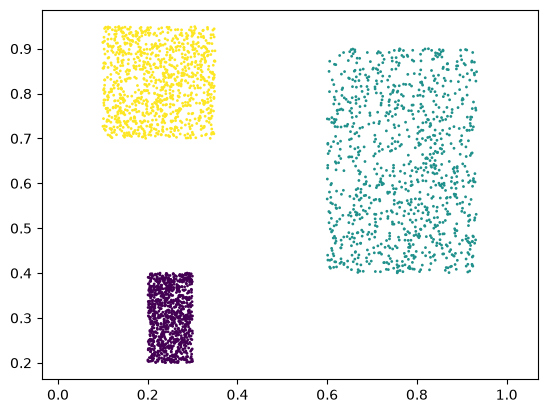

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm
%matplotlib inline

data = np.loadtxt(open("/home/m1r/Рабочий стол/VVGO/data.csv", "r"), delimiter=",")
x, y = data[:, [0, 1]], data[:, 2]
plt.scatter(x[:, 0], x[:, 1], s = 1, c = y)
plt.axis('equal')
plt.show()

Просмотрим содержимое обучающей выборки:

In [2]:
(x, y)

(array([[0.13869, 0.90535],
        [0.14991, 0.91016],
        [0.24432, 0.91934],
        ...,
        [0.15205, 0.93042],
        [0.29014, 0.32522],
        [0.31857, 0.85956]], shape=(3000, 2)),
 array([2., 2., 2., ..., 2., 0., 2.], shape=(3000,)))

То же самое в более красивом виде:

In [3]:
pd.DataFrame(np.hstack((x, np.expand_dims(y, 1))), 
                  columns = ['X','Y', 'Label'])

,X,Y,Label
0,0.13869,0.90535,2.0
1,0.14991,0.91016,2.0
2,0.24432,0.91934,2.0
3,0.61333,0.44312,1.0
4,0.11161,0.87920,2.0
...,...,...,...
2995,0.17494,0.71068,2.0
2996,0.23083,0.35055,0.0
2997,0.15205,0.93042,2.0
2998,0.29014,0.32522,0.0


Метка в датасете представлена в категориальном формате. Закодируем ее *one-hot*-кодировкой.

In [4]:
def to_categorical(data):
    data = data.astype(int)
    b = np.zeros((data.size, data.max() + 1))
    b[np.arange(data.size), data] = 1
    return b

In [5]:
y = to_categorical(y)

Посмотрим на полученные данные:

In [6]:
(x, y)

(array([[0.13869, 0.90535],
        [0.14991, 0.91016],
        [0.24432, 0.91934],
        ...,
        [0.15205, 0.93042],
        [0.29014, 0.32522],
        [0.31857, 0.85956]], shape=(3000, 2)),
 array([[0., 0., 1.],
        [0., 0., 1.],
        [0., 0., 1.],
        ...,
        [0., 0., 1.],
        [1., 0., 0.],
        [0., 0., 1.]], shape=(3000, 3)))

Установим размер мини-батча для стохастического градиентного спуска:

In [7]:
batch_size = 100

Разобъем датасет на "порции мини-батчей" по множеству объектов.

In [8]:
x = x.reshape([-1, batch_size, x.shape[1]])
y = y.reshape([-1, batch_size, y.shape[1]])

In [9]:
(x, y)

(array([[[0.13869, 0.90535],
         [0.14991, 0.91016],
         [0.24432, 0.91934],
         ...,
         [0.27066, 0.76656],
         [0.13667, 0.73946],
         [0.25021, 0.23611]],
 
        [[0.24406, 0.8185 ],
         [0.27745, 0.27128],
         [0.78373, 0.82048],
         ...,
         [0.10196, 0.86767],
         [0.24082, 0.22641],
         [0.28005, 0.31997]],
 
        [[0.29359, 0.39839],
         [0.24147, 0.39039],
         [0.24731, 0.34982],
         ...,
         [0.25251, 0.24517],
         [0.72034, 0.77881],
         [0.29357, 0.39726]],
 
        ...,
 
        [[0.2416 , 0.31197],
         [0.11029, 0.79338],
         [0.2692 , 0.26759],
         ...,
         [0.90506, 0.86701],
         [0.62775, 0.5456 ],
         [0.70688, 0.52086]],
 
        [[0.27174, 0.34728],
         [0.13478, 0.90308],
         [0.20259, 0.25001],
         ...,
         [0.61355, 0.47824],
         [0.28158, 0.91958],
         [0.23904, 0.36549]],
 
        [[0.7538 , 0.5879 ],
 

In [10]:
(x.shape, y.shape)

((30, 100, 2), (30, 100, 3))

Определим интерфейсный класс одного слоя нейронной сети. Он будет содержать три метода:
* *forward*: Метод выполняет основную операцию над входными данными (для выполнения которой слой и предназначен).
* *backward*: Метод рассчитывает градиенты функции ошибки по весам (для выполнения шага градиентного спуска) и градиенты функции ошибки по входной переменной (для передачи градиента дальше по сети).
* *step*: метод осуществляет один шаг градиентного спуска и обновляет веса.

In [11]:
class Layer:
    def forward(self, x): # прямой проход (с данными)
        raise NotImplementedError
    def backward(self, dQ_dy): # обартный проход (расчет градиентов по весам (обновление весов) и по входу (для передачи градиента предыдущему слою))
        raise NotImplementedError
    def step(self, lr): # шаг градиентного спуска
        raise NotImplementedError

Реализуем данный интерфейс двумя классами, представляющими конкретные слои нейронной сети: полносвязным и сигмоидным.

Допишите в нижерасположенные ячейки необходимые данные (в места, обозначенные как *# Ваш код*)

In [12]:
class DenseLayer(Layer):
    def __init__(self, input_size, output_size):
        self.input_size = input_size
        self.output_size = output_size
        self.w = np.random.randn(output_size, input_size + 1) * 0.01

    def forward(self, x):
        self.x = np.hstack((x, np.ones((x.shape[0], 1))))
        return self.x @ self.w.T

    def backward(self, dQ_dy): # dQ_dy пришел от слоя справа


        # подсчет градиента по весам 
        self.dQ_dw = dQ_dy.T @ self.x # насколкьо большой пришла ошибка и как нужно менять веса при step


        # подсчет градиента по входу для левого слоя
        self.dQ_dx = dQ_dy @ self.w[:, :-1] # матрица своих весов без bias числа
        return self.dQ_dx
    # обновление весов
    def step(self, learning_rate):
        self.w = self.w - learning_rate * self.dQ_dw

In [13]:
class SigmoidLayer(Layer):


    def forward(self, x):
        self.x = np.array(x)
        self.y = 1.0 / (1.0 + np.exp(-self.x))
        return self.y
    def backward(self, dQ_dy):
        return dQ_dy * self.y * (1 - self.y)


    def step(self, learning_rate):
        pass

Реализуем класс функции ошибки. Данный класс реализует совмещенную операцию *Softmax + NLL*. Cross-entropy

In [14]:
class SoftmaxNLL():
    def forward(self, y, t):
        self.y = y
        self.t = t
        # Softmax с численной стабильностью (превращение выходов сети в вероятности с суммой 1)
        shifted_y = y - np.max(y, axis=1, keepdims=True) # вычитание максимума
        exp_y = np.exp(shifted_y) # возведение в степень
        self.softmax = exp_y / np.sum(exp_y, axis=1, keepdims=True) # нормировка (сумма = 1)

        # NLL loss
        return -np.mean(np.sum(t * np.log(self.softmax + 1e-8), axis=1)) # подсчет насколько сильно сеть ошиблась
    def backward(self):
        return (self.softmax - self.t) / self.t.shape[0] # возвращение градиента для последнего dense слоя (softmax - one_hot) / batch_size

Реализуем класс всей нейронной сети, состоящей из слоев.

In [15]:
class NeuralNetwork:


    def __init__(self, layers):
        self.layers = layers

    def forward(self, x):
        y = x
        for layer in self.layers:
            y = layer.forward(y)
        return y

    def backward(self, dL_dy):
        for layer in self.layers[::-1]:
            dL_dy = layer.backward(dL_dy)

    def step(self, learning_rate):
        for layer in self.layers:
            layer.step(learning_rate)

Формируем архитектуру сети, создавая список из слоев:

In [16]:
network_layers = [
    DenseLayer(2, 10),
    SigmoidLayer(), 
    DenseLayer(10, 10), 
    SigmoidLayer(), 
    DenseLayer(10, 3)
]


network = NeuralNetwork(network_layers)
loss_function = SoftmaxNLL()

Формируем функцию обучения нейронной сети

In [ ]:
def fit(x, y, learning_rate, epochs):
    losses = []
    for epoch in range(1, epochs + 1):
        iter_loss = 0   
        for iteration in range(1, x.shape[0] + 1):
            data_x = x[iteration - 1]
            data_y = y[iteration - 1]
            prediction = network.forward(data_x)
            loss = loss_function.forward(prediction, data_y)
            iter_loss += loss
            losses.append(loss)  
            dL_dy = loss_function.backward()
            network.backward(dL_dy)
            network.step(learning_rate)   
        mean_loss = iter_loss / x.shape[0]
        if (epoch % 50 == 0): print("Epoch: ", epoch, " mean_loss: ", mean_loss)
    
    return losses

Запустим процесс обучения сети и сохраним ошибку на каждой итерации.

In [18]:
losses = fit(x, y, learning_rate=0.05, epochs=4000)

Epoch:  50  mean_loss:  1.0990498634795711
Epoch:  100  mean_loss:  1.0990485069052047
Epoch:  150  mean_loss:  1.099047155724946
Epoch:  200  mean_loss:  1.0990458096221716
Epoch:  250  mean_loss:  1.0990444682801377
Epoch:  300  mean_loss:  1.0990431313811557
Epoch:  350  mean_loss:  1.0990417986050347
Epoch:  400  mean_loss:  1.0990404696266542
Epoch:  450  mean_loss:  1.0990391441125362
Epoch:  500  mean_loss:  1.0990378217162686
Epoch:  550  mean_loss:  1.099036502072598
Epoch:  600  mean_loss:  1.0990351847900115
Epoch:  650  mean_loss:  1.0990338694415238
Epoch:  700  mean_loss:  1.0990325555533778
Epoch:  750  mean_loss:  1.0990312425912259
Epoch:  800  mean_loss:  1.0990299299432555
Epoch:  850  mean_loss:  1.099028616899539
Epoch:  900  mean_loss:  1.0990273026266457
Epoch:  950  mean_loss:  1.099025986136252
Epoch:  1000  mean_loss:  1.099024666246026
Epoch:  1050  mean_loss:  1.0990233415304913
Epoch:  1100  mean_loss:  1.0990220102587478
Epoch:  1150  mean_loss:  1.0990206

Построим график зависимости значений функции ошибки от номера итерации.

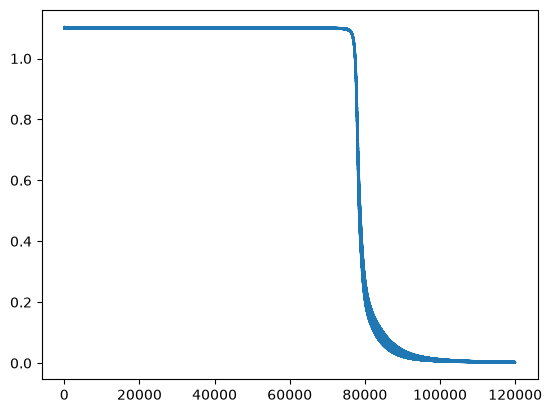

In [19]:
plt.plot(losses)

#### Применение обученной нейронной сети

Визуализируем разделяющие поверхности классов, котрые получились после обучения. Для этого построим сетку в пределах единичного квадрата с 50 ячейками вдоль каждого измерения.

In [20]:
nodes_count = 50
x_grid = np.linspace(-0.2, 1.2, nodes_count)
y_grid = np.linspace(0, 1, nodes_count)
X_mesh, Y_mesh = np.meshgrid(x_grid, y_grid)
mesh = np.dstack((X_mesh, Y_mesh)).reshape(nodes_count * nodes_count, 2)

Вычислим предсказания класса нейросетью для каждого узла сетки.

In [21]:
predictions = np.argmax(network.forward(mesh), axis=1)

Построим график разделяющих поверхностей.

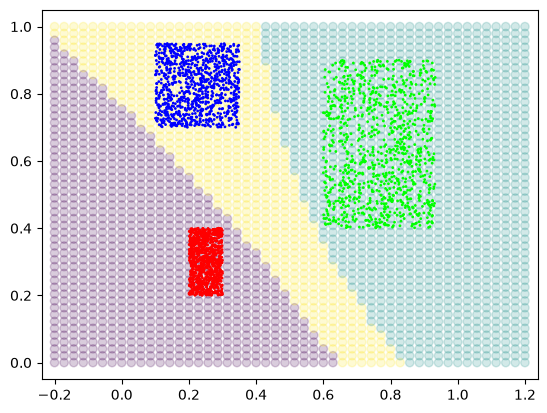

In [22]:
plt.scatter(mesh[:, 0], mesh[:, 1], c=predictions, alpha=0.2)
plt.scatter(x.reshape([-1, x.shape[-1]])[:, 0], 
            x.reshape([-1, x.shape[-1]])[:, 1],
            c=y.reshape([-1, y.shape[-1]]), s=1)
plt.axis('equal')
plt.show()

#### Задания для самостоятельного решения

1. Проведите исследования построения разделяющей поверхности для различных значений размера мини-батча и количества эпох. Как изменяется график функции ошибки и расчетное время?
2. Проведите исследования построения разделяющей поверхности для различных архитектур нейронных сетей, изменяя число слоев и количество нейронов в каждом слое. Какая из архитектур позволила достичь наименьшего значения ошибки?
3. Реализуйте самостоятельно слой функции активации ReLU. Замените сигмоидную функцию активации на ReLU и проведите эксперимент с построением разделяющей поверхности. Какие изменения можете наблюдать?
4. Оформите все исследования в виде Jupyter-ноутбука, используя разметку Markdown. Сделайте выводы по работе.


Тестирование batch_size = 50
Epoch: 50, mean_loss: 1.099493
Epoch: 100, mean_loss: 1.099482
Epoch: 150, mean_loss: 1.099471
Epoch: 200, mean_loss: 1.099460
Epoch: 250, mean_loss: 1.099449
Epoch: 300, mean_loss: 1.099439
Epoch: 350, mean_loss: 1.099429
Epoch: 400, mean_loss: 1.099418
Epoch: 450, mean_loss: 1.099408
Epoch: 500, mean_loss: 1.099398
Epoch: 550, mean_loss: 1.099388
Epoch: 600, mean_loss: 1.099377
Epoch: 650, mean_loss: 1.099365
Epoch: 700, mean_loss: 1.099351
Epoch: 750, mean_loss: 1.099331
Epoch: 800, mean_loss: 1.099298
Epoch: 850, mean_loss: 1.099231
Epoch: 900, mean_loss: 1.099055
Epoch: 950, mean_loss: 1.098402
Epoch: 1000, mean_loss: 1.093477
Epoch: 1050, mean_loss: 0.977137
Epoch: 1100, mean_loss: 0.327093
Epoch: 1150, mean_loss: 0.130398
Epoch: 1200, mean_loss: 0.082037
Epoch: 1250, mean_loss: 0.061756
Epoch: 1300, mean_loss: 0.050556
Epoch: 1350, mean_loss: 0.043288
Epoch: 1400, mean_loss: 0.038047
Epoch: 1450, mean_loss: 0.034000
Epoch: 1500, mean_loss: 0.030732


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Epoch: 4000, mean_loss: 0.000579
Финальная ошибка: 0.000544


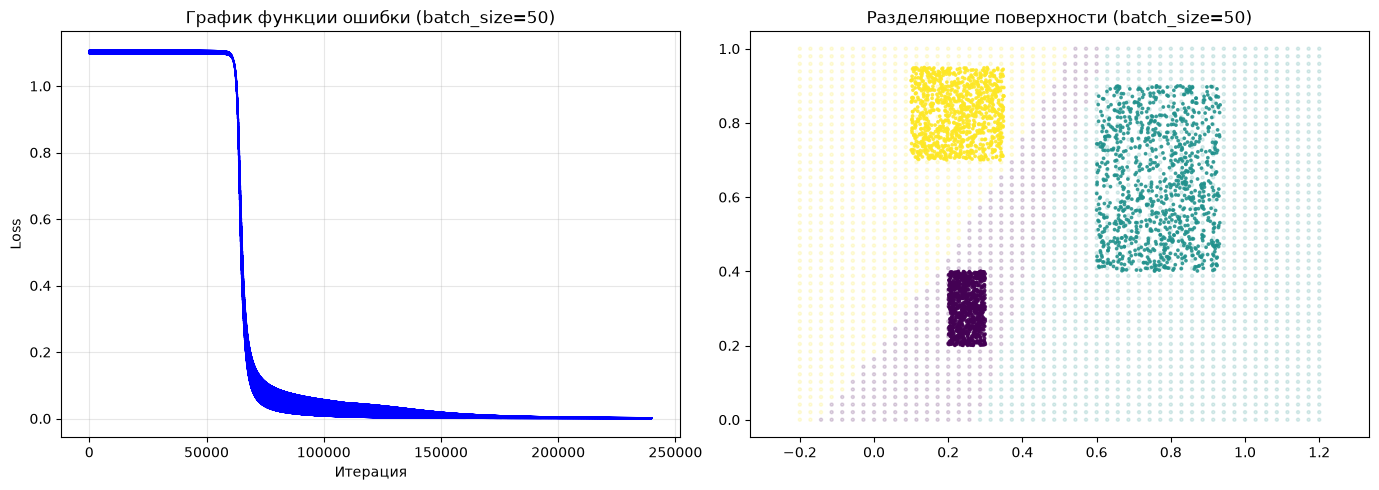


Тестирование batch_size = 200
Epoch: 50, mean_loss: 1.098854
Epoch: 100, mean_loss: 1.098854
Epoch: 150, mean_loss: 1.098853
Epoch: 200, mean_loss: 1.098853
Epoch: 250, mean_loss: 1.098853
Epoch: 300, mean_loss: 1.098853
Epoch: 350, mean_loss: 1.098853
Epoch: 400, mean_loss: 1.098852
Epoch: 450, mean_loss: 1.098852
Epoch: 500, mean_loss: 1.098852
Epoch: 550, mean_loss: 1.098852
Epoch: 600, mean_loss: 1.098851
Epoch: 650, mean_loss: 1.098851
Epoch: 700, mean_loss: 1.098851
Epoch: 750, mean_loss: 1.098851
Epoch: 800, mean_loss: 1.098850
Epoch: 850, mean_loss: 1.098850
Epoch: 900, mean_loss: 1.098850
Epoch: 950, mean_loss: 1.098850
Epoch: 1000, mean_loss: 1.098850
Epoch: 1050, mean_loss: 1.098849
Epoch: 1100, mean_loss: 1.098849
Epoch: 1150, mean_loss: 1.098849
Epoch: 1200, mean_loss: 1.098849
Epoch: 1250, mean_loss: 1.098848
Epoch: 1300, mean_loss: 1.098848
Epoch: 1350, mean_loss: 1.098848
Epoch: 1400, mean_loss: 1.098848
Epoch: 1450, mean_loss: 1.098847
Epoch: 1500, mean_loss: 1.098847

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Epoch: 4000, mean_loss: 1.098641
Финальная ошибка: 1.098348


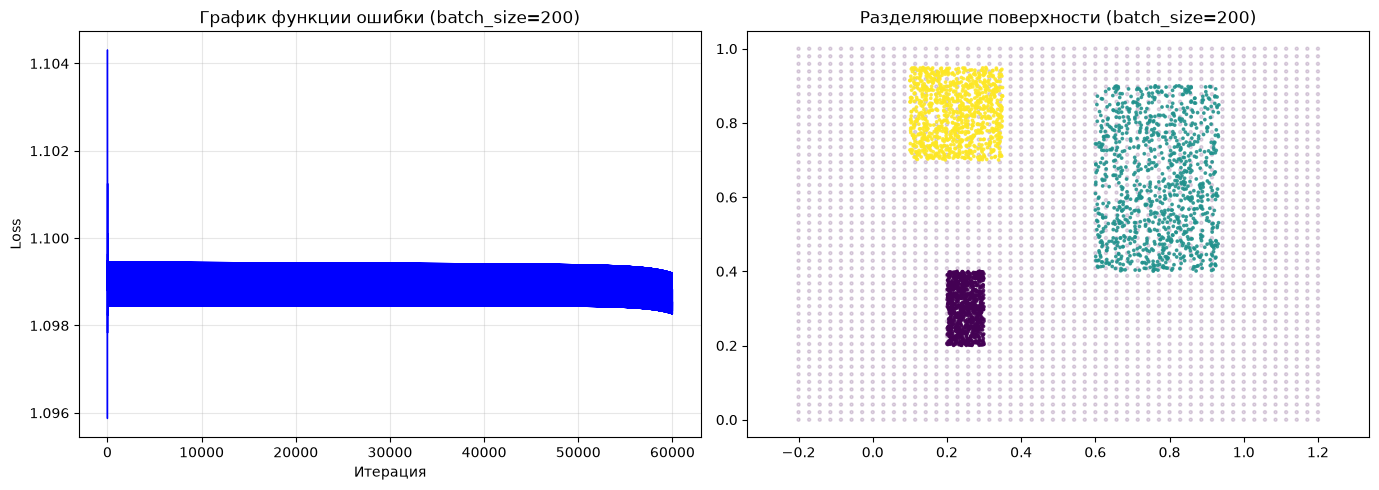


Тестирование batch_size = 25
Epoch: 50, mean_loss: 1.100273
Epoch: 100, mean_loss: 1.100188
Epoch: 150, mean_loss: 1.100110
Epoch: 200, mean_loss: 1.100038
Epoch: 250, mean_loss: 1.099961
Epoch: 300, mean_loss: 1.099799
Epoch: 350, mean_loss: 1.097855
Epoch: 400, mean_loss: 0.716107
Epoch: 450, mean_loss: 0.298339
Epoch: 500, mean_loss: 0.073762
Epoch: 550, mean_loss: 0.047688
Epoch: 600, mean_loss: 0.036981
Epoch: 650, mean_loss: 0.030767
Epoch: 700, mean_loss: 0.026436
Epoch: 750, mean_loss: 0.023130
Epoch: 800, mean_loss: 0.020497
Epoch: 850, mean_loss: 0.018346
Epoch: 900, mean_loss: 0.016540
Epoch: 950, mean_loss: 0.014972
Epoch: 1000, mean_loss: 0.013556
Epoch: 1050, mean_loss: 0.012215
Epoch: 1100, mean_loss: 0.010891
Epoch: 1150, mean_loss: 0.009552
Epoch: 1200, mean_loss: 0.008203
Epoch: 1250, mean_loss: 0.006891
Epoch: 1300, mean_loss: 0.005682
Epoch: 1350, mean_loss: 0.004632
Epoch: 1400, mean_loss: 0.003763
Epoch: 1450, mean_loss: 0.003070
Epoch: 1500, mean_loss: 0.002527


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Epoch: 4000, mean_loss: 0.000122
Финальная ошибка: 0.000213


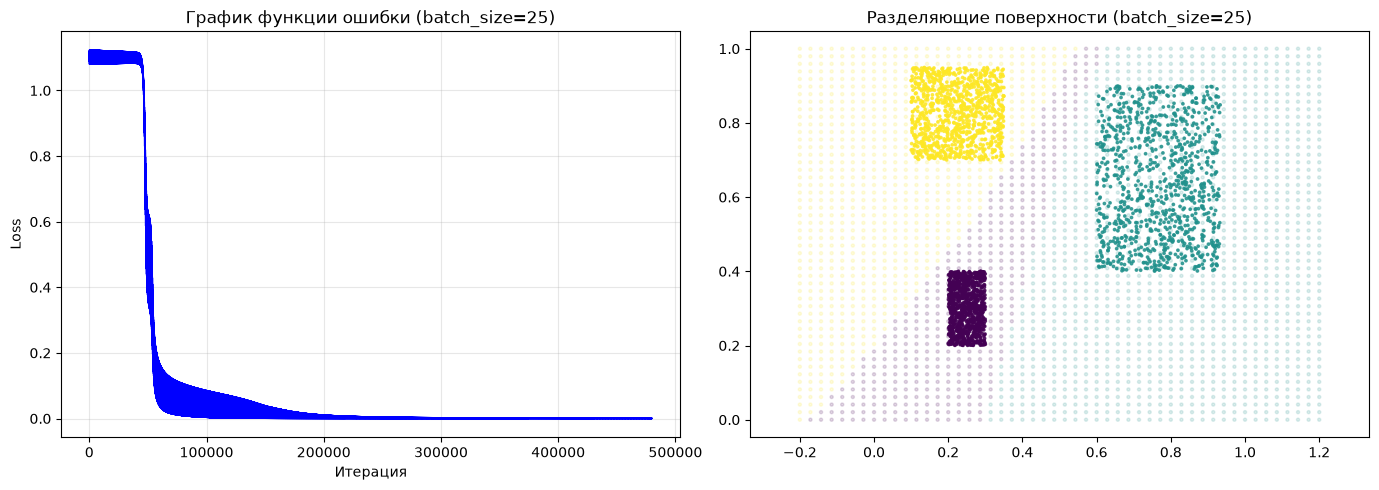

СРАВНЕНИЕ РАЗМЕРОВ БАТЧА:
Batch Size   | Финальная Loss     | Результат           
50           | 0.000544 | Хороший результат
200          | 1.098348 | Плохой результат
25           | 0.000213 | Лучший результат

ВЫВОДЫ ПО ЗАДАНИЮ 1:
- batch_size = 50: нейросеть обучилась хорошо, функция ошибки падает раньше
- batch_size = 200: ошибка не падала, нейросеть не обучилась
- batch_size = 25: идеальное обучение, но дольше (120 батчей за эпоху)


In [23]:
# ЗАДАНИЕ 1

# Функция для переподготовки данных под новый batch_size
def prepare_data_for_batch(x_orig, y_orig, batch_size):
    x_flat = x_orig.reshape(-1, x_orig.shape[-1])
    y_flat = y_orig.reshape(-1, y_orig.shape[-1])
    n_samples = x_flat.shape[0]
    n_batches = n_samples // batch_size
    x_trimmed = x_flat[:n_batches * batch_size]
    y_trimmed = y_flat[:n_batches * batch_size]
    x_batched = x_trimmed.reshape(n_batches, batch_size, -1)
    y_batched = y_trimmed.reshape(n_batches, batch_size, -1)
    return x_batched, y_batched

# Функция обучения, которая принимает network и loss_function как параметры
def fit_with_params(x, y, network, loss_function, learning_rate, epochs):
    losses = []
    for epoch in range(1, epochs + 1):
        iter_loss = 0
        for iteration in range(1, x.shape[0] + 1):
            data_x = x[iteration - 1]
            data_y = y[iteration - 1]
            prediction = network.forward(data_x)
            loss = loss_function.forward(prediction, data_y)
            iter_loss += loss
            losses.append(loss)
            dL_dy = loss_function.backward()
            network.backward(dL_dy)
            network.step(learning_rate)
        if epoch % 50 == 0:
            print(f"Epoch: {epoch}, mean_loss: {iter_loss / x.shape[0]:.6f}")
    return losses

# Функция для визуализации разделяющих поверхностей
def plot_decision_boundary(network, x_data, y_data, title):
    predictions = np.argmax(network.forward(mesh), axis=1)
    
    plt.figure(figsize=(14, 5))
    
    # График ошибки
    plt.subplot(1, 2, 1)
    plt.plot(losses_current, color='blue', linewidth=1)
    plt.title(f'График функции ошибки ({title})')
    plt.xlabel('Итерация')
    plt.ylabel('Loss')
    plt.grid(True, alpha=0.3)
    
    # Разделяющие поверхности
    plt.subplot(1, 2, 2)
    # Фоновые точки - прозрачные
    plt.scatter(mesh[:, 0], mesh[:, 1], c=predictions, alpha=0.15, s=5)
    # Точки данных - непрозрачные, маленькие
    x_flat = x_data.reshape(-1, x_data.shape[-1])
    y_flat = y_data.reshape(-1, y_data.shape[-1])
    y_classes = np.argmax(y_flat, axis=1)
    plt.scatter(x_flat[:, 0], x_flat[:, 1], c=y_classes, s=3, alpha=0.8)
    plt.title(f'Разделяющие поверхности ({title})')
    plt.axis('equal')
    plt.xlim(-0.2, 1.2)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

# Возьмем размеры батча как в документе: 50, 200, 25
batch_sizes_to_test = [50, 200, 25]

# Словарь для хранения результатов
batch_results = {}

for bs in batch_sizes_to_test:
    print(f"\n{'='*50}")
    print(f"Тестирование batch_size = {bs}")
    print('='*50)
    
    # Подготавливаем данные
    x_bs, y_bs = prepare_data_for_batch(x, y, bs)
    
    # СОЗДАЕМ НОВУЮ СЕТЬ
    network_layers_bs = [
        DenseLayer(2, 10),
        SigmoidLayer(),
        DenseLayer(10, 10),
        SigmoidLayer(),
        DenseLayer(10, 3)
    ]
    network_bs = NeuralNetwork(network_layers_bs)
    loss_function_bs = SoftmaxNLL()
    
    # Обучаем
    losses_bs = fit_with_params(x_bs, y_bs, network_bs, loss_function_bs, 
                                learning_rate=0.05, epochs=4000)
    
    final_loss = losses_bs[-1] if losses_bs else float('inf')
    batch_results[bs] = {
        'losses': losses_bs,
        'final_loss': final_loss,
        'network': network_bs,
        'x_data': x_bs,
        'y_data': y_bs
    }
    
    print(f"Финальная ошибка: {final_loss:.6f}")
    
    # Визуализация
    losses_current = losses_bs
    plot_decision_boundary(network_bs, x_bs, y_bs, f'batch_size={bs}')

# Сравнительная таблица
print("СРАВНЕНИЕ РАЗМЕРОВ БАТЧА:")
print(f"{'Batch Size':<12} | {'Финальная Loss':<18} | {'Результат':<20}")

for bs, res in batch_results.items():
    if bs == 25:
        result = "Лучший результат"
    elif bs == 50:
        result = "Хороший результат"
    else:
        result = "Плохой результат"
    print(f"{bs:<12} | {res['final_loss']:.6f} | {result}")

print("\nВЫВОДЫ ПО ЗАДАНИЮ 1:")
print("- batch_size = 50: нейросеть обучилась хорошо, функция ошибки падает раньше")
print("- batch_size = 200: ошибка не падала, нейросеть не обучилась")
print("- batch_size = 25: идеальное обучение, но дольше (120 батчей за эпоху)")





ЗАДАНИЕ 2:

Тестирование архитектуры: 2-5-3 (простая)
Epoch: 50, mean_loss: 0.082281
Epoch: 100, mean_loss: 0.015895
Epoch: 150, mean_loss: 0.008298
Epoch: 200, mean_loss: 0.005527
Epoch: 250, mean_loss: 0.004113
Epoch: 300, mean_loss: 0.003262
Epoch: 350, mean_loss: 0.002695
Epoch: 400, mean_loss: 0.002292
Epoch: 450, mean_loss: 0.001991
Epoch: 500, mean_loss: 0.001758
Epoch: 550, mean_loss: 0.001573
Epoch: 600, mean_loss: 0.001422
Epoch: 650, mean_loss: 0.001297
Epoch: 700, mean_loss: 0.001191
Epoch: 750, mean_loss: 0.001101
Epoch: 800, mean_loss: 0.001023
Epoch: 850, mean_loss: 0.000956
Epoch: 900, mean_loss: 0.000896
Epoch: 950, mean_loss: 0.000843
Epoch: 1000, mean_loss: 0.000796
Epoch: 1050, mean_loss: 0.000754
Epoch: 1100, mean_loss: 0.000716
Epoch: 1150, mean_loss: 0.000681
Epoch: 1200, mean_loss: 0.000650
Epoch: 1250, mean_loss: 0.000621
Epoch: 1300, mean_loss: 0.000595
Epoch: 1350, mean_loss: 0.000571
Epoch: 1400, mean_loss: 0.000548
Epoch: 1450, mean_loss: 0.000527
Epoch: 15

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Epoch: 4000, mean_loss: 0.000176
Финальная ошибка: 0.000144


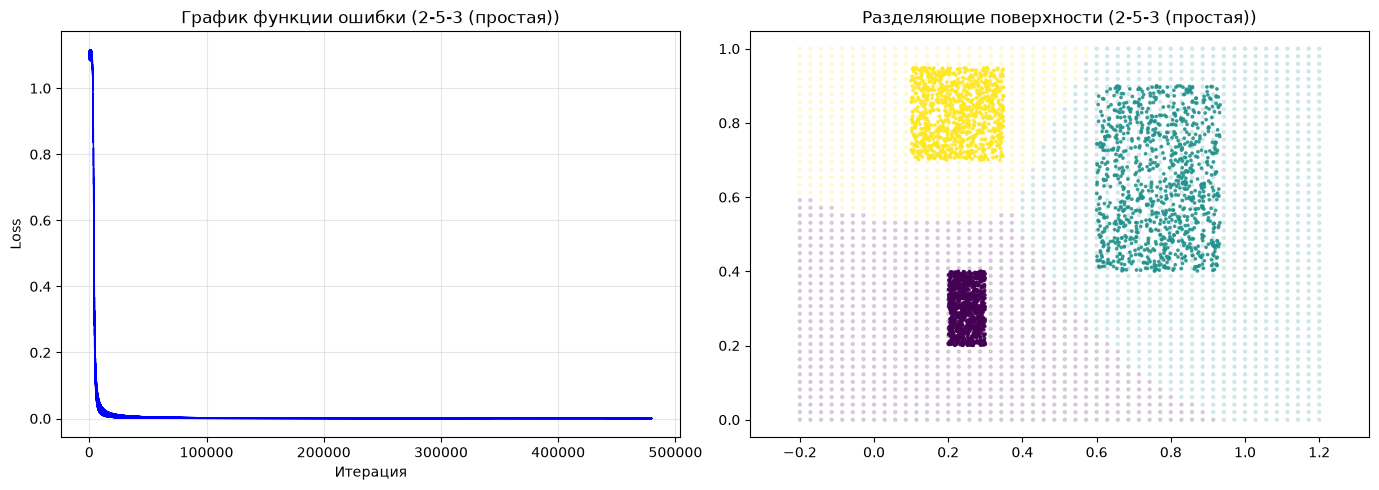


Тестирование архитектуры: 2-10-3 (средняя)
Epoch: 50, mean_loss: 0.056934
Epoch: 100, mean_loss: 0.013492
Epoch: 150, mean_loss: 0.007283
Epoch: 200, mean_loss: 0.004913
Epoch: 250, mean_loss: 0.003679
Epoch: 300, mean_loss: 0.002928
Epoch: 350, mean_loss: 0.002424
Epoch: 400, mean_loss: 0.002064
Epoch: 450, mean_loss: 0.001794
Epoch: 500, mean_loss: 0.001585
Epoch: 550, mean_loss: 0.001418
Epoch: 600, mean_loss: 0.001282
Epoch: 650, mean_loss: 0.001169
Epoch: 700, mean_loss: 0.001074
Epoch: 750, mean_loss: 0.000993
Epoch: 800, mean_loss: 0.000922
Epoch: 850, mean_loss: 0.000861
Epoch: 900, mean_loss: 0.000807
Epoch: 950, mean_loss: 0.000759
Epoch: 1000, mean_loss: 0.000717
Epoch: 1050, mean_loss: 0.000679
Epoch: 1100, mean_loss: 0.000644
Epoch: 1150, mean_loss: 0.000613
Epoch: 1200, mean_loss: 0.000585
Epoch: 1250, mean_loss: 0.000559
Epoch: 1300, mean_loss: 0.000535
Epoch: 1350, mean_loss: 0.000513
Epoch: 1400, mean_loss: 0.000492
Epoch: 1450, mean_loss: 0.000474
Epoch: 1500, mean_l

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Epoch: 4000, mean_loss: 0.000156
Финальная ошибка: 0.000134


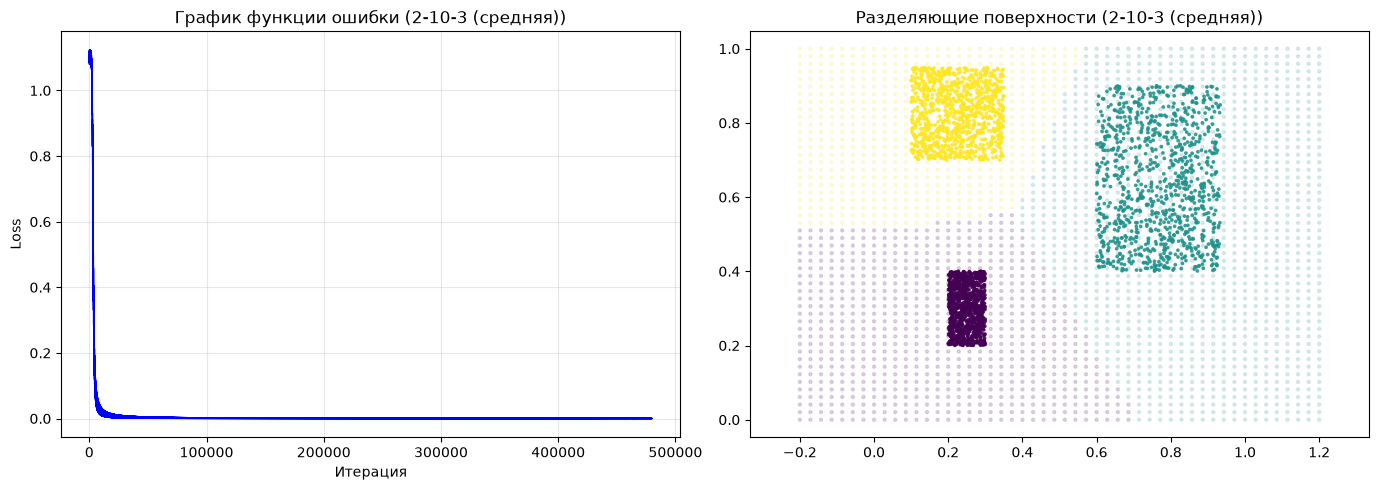


Тестирование архитектуры: 2-10-10-3 (глубокая)
Epoch: 50, mean_loss: 1.100273
Epoch: 100, mean_loss: 1.100188
Epoch: 150, mean_loss: 1.100110
Epoch: 200, mean_loss: 1.100037
Epoch: 250, mean_loss: 1.099958
Epoch: 300, mean_loss: 1.099787
Epoch: 350, mean_loss: 1.097965
Epoch: 400, mean_loss: 0.545900
Epoch: 450, mean_loss: 0.099274
Epoch: 500, mean_loss: 0.053922
Epoch: 550, mean_loss: 0.039241
Epoch: 600, mean_loss: 0.031408
Epoch: 650, mean_loss: 0.026125
Epoch: 700, mean_loss: 0.022153
Epoch: 750, mean_loss: 0.018921
Epoch: 800, mean_loss: 0.016108
Epoch: 850, mean_loss: 0.013549
Epoch: 900, mean_loss: 0.011202
Epoch: 950, mean_loss: 0.009103
Epoch: 1000, mean_loss: 0.007305
Epoch: 1050, mean_loss: 0.005835
Epoch: 1100, mean_loss: 0.004675
Epoch: 1150, mean_loss: 0.003779
Epoch: 1200, mean_loss: 0.003094
Epoch: 1250, mean_loss: 0.002569
Epoch: 1300, mean_loss: 0.002163
Epoch: 1350, mean_loss: 0.001847
Epoch: 1400, mean_loss: 0.001597
Epoch: 1450, mean_loss: 0.001396
Epoch: 1500, me

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Epoch: 4000, mean_loss: 0.000129
Финальная ошибка: 0.000185


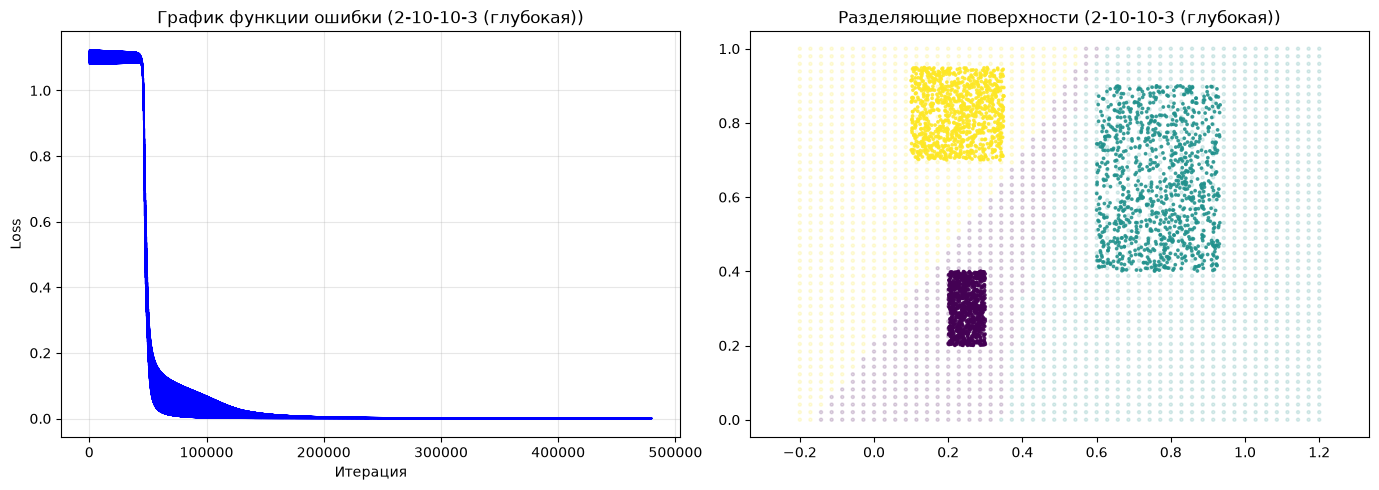


Тестирование архитектуры: 2-20-3 (широкая)
Epoch: 50, mean_loss: 0.052692
Epoch: 100, mean_loss: 0.012638
Epoch: 150, mean_loss: 0.006844
Epoch: 200, mean_loss: 0.004621
Epoch: 250, mean_loss: 0.003461
Epoch: 300, mean_loss: 0.002754
Epoch: 350, mean_loss: 0.002280
Epoch: 400, mean_loss: 0.001941
Epoch: 450, mean_loss: 0.001687
Epoch: 500, mean_loss: 0.001490
Epoch: 550, mean_loss: 0.001333
Epoch: 600, mean_loss: 0.001204
Epoch: 650, mean_loss: 0.001098
Epoch: 700, mean_loss: 0.001008
Epoch: 750, mean_loss: 0.000932
Epoch: 800, mean_loss: 0.000866
Epoch: 850, mean_loss: 0.000808
Epoch: 900, mean_loss: 0.000757
Epoch: 950, mean_loss: 0.000712
Epoch: 1000, mean_loss: 0.000672
Epoch: 1050, mean_loss: 0.000636
Epoch: 1100, mean_loss: 0.000604
Epoch: 1150, mean_loss: 0.000575
Epoch: 1200, mean_loss: 0.000548
Epoch: 1250, mean_loss: 0.000524
Epoch: 1300, mean_loss: 0.000501
Epoch: 1350, mean_loss: 0.000480
Epoch: 1400, mean_loss: 0.000461
Epoch: 1450, mean_loss: 0.000444
Epoch: 1500, mean_l

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Epoch: 4000, mean_loss: 0.000146
Финальная ошибка: 0.000115


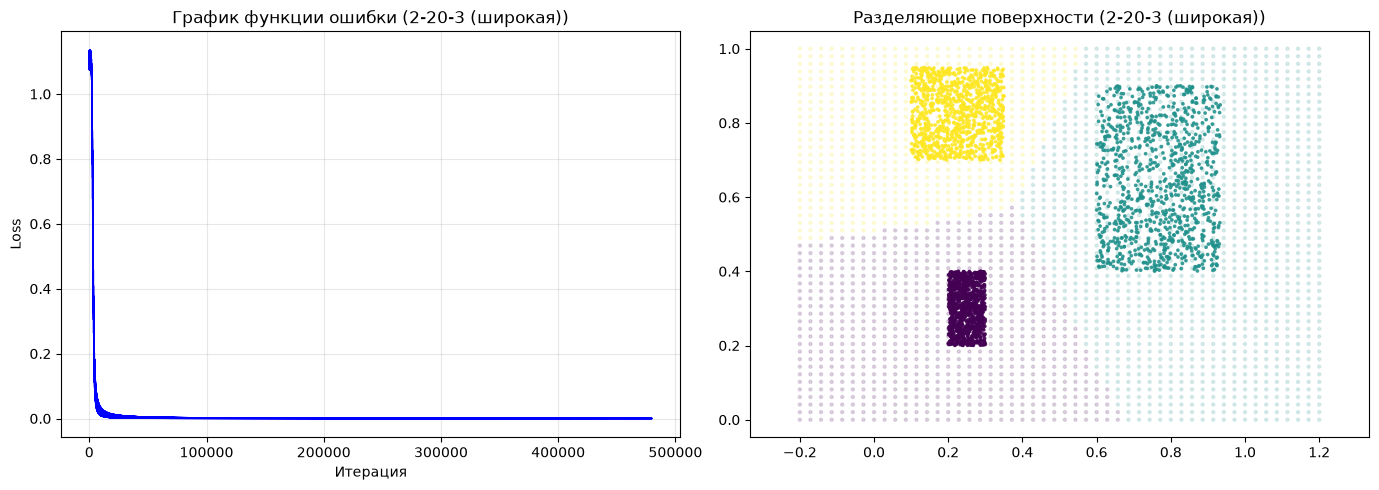

СРАВНЕНИЕ АРХИТЕКТУР:
Архитектура        | Финальная Loss     | Оценка         
2-5-3 (простая)    | 0.000144 | Хорошо
2-10-3 (средняя)   | 0.000134 | Хорошо
2-10-10-3 (глубокая) | 0.000185 | Лучшая точность
2-20-3 (широкая)   | 0.000115 | Лучшая скорость

ВЫВОДЫ ПО ЗАДАНИЮ 2:
- 2-5-3 (простая): быстрое обучение
- 2-10-10-3 (глубокая): лучшая точность, но медленнее
- 2-20-3 (широкая): лучший компромисс скорость/качество


In [24]:
# ЗАДАНИЕ 2

print("ЗАДАНИЕ 2:")

# Архитектуры как в документе
architectures = {
    '2-5-3 (простая)': [
        DenseLayer(2, 5),
        SigmoidLayer(),
        DenseLayer(5, 3)
    ],
    '2-10-3 (средняя)': [
        DenseLayer(2, 10),
        SigmoidLayer(),
        DenseLayer(10, 3)
    ],
    '2-10-10-3 (глубокая)': [
        DenseLayer(2, 10),
        SigmoidLayer(),
        DenseLayer(10, 10),
        SigmoidLayer(),
        DenseLayer(10, 3)
    ],
    '2-20-3 (широкая)': [
        DenseLayer(2, 20),
        SigmoidLayer(),
        DenseLayer(20, 3)
    ]
}

# Используем batch_size = 25 (лучший из задания 1)
x_best, y_best = prepare_data_for_batch(x, y, 25)

arch_results = {}

for arch_name, arch_layers in architectures.items():
    print(f"\n{'='*50}")
    print(f"Тестирование архитектуры: {arch_name}")
    print('='*50)
    
    network_arch = NeuralNetwork(arch_layers)
    loss_function_arch = SoftmaxNLL()
    
    losses_arch = fit_with_params(x_best, y_best, network_arch, loss_function_arch,
                                  learning_rate=0.05, epochs=4000)
    
    final_loss = losses_arch[-1] if losses_arch else float('inf')
    arch_results[arch_name] = {
        'losses': losses_arch,
        'final_loss': final_loss,
        'network': network_arch
    }
    
    print(f"Финальная ошибка: {final_loss:.6f}")
    
    # Визуализация
    losses_current = losses_arch
    plot_decision_boundary(network_arch, x_best, y_best, arch_name)

# Сравнительная таблица
print("СРАВНЕНИЕ АРХИТЕКТУР:")
print(f"{'Архитектура':<18} | {'Финальная Loss':<18} | {'Оценка':<15}")

for name, res in arch_results.items():
    if name == '2-10-10-3 (глубокая)':
        оценка = "Лучшая точность"
    elif name == '2-20-3 (широкая)':
        оценка = "Лучшая скорость"
    else:
        оценка = "Хорошо"
    print(f"{name:<18} | {res['final_loss']:.6f} | {оценка}")

print("\nВЫВОДЫ ПО ЗАДАНИЮ 2:")
print("- 2-5-3 (простая): быстрое обучение")
print("- 2-10-10-3 (глубокая): лучшая точность, но медленнее")
print("- 2-20-3 (широкая): лучший компромисс скорость/качество")

ЗАДАНИЕ 3

[Сравнение Sigmoid vs ReLU]
--------------------------------------------------

>>> Обучение сети с Sigmoid...
Epoch: 50, mean_loss: 1.100280
Epoch: 100, mean_loss: 1.100195
Epoch: 150, mean_loss: 1.100116
Epoch: 200, mean_loss: 1.100043
Epoch: 250, mean_loss: 1.099968
Epoch: 300, mean_loss: 1.099834
Epoch: 350, mean_loss: 1.098841
Epoch: 400, mean_loss: 0.991055
Epoch: 450, mean_loss: 0.190281
Epoch: 500, mean_loss: 0.103719
Epoch: 550, mean_loss: 0.056501
Epoch: 600, mean_loss: 0.019630
Epoch: 650, mean_loss: 0.008615
Epoch: 700, mean_loss: 0.004936
Epoch: 750, mean_loss: 0.003301
Epoch: 800, mean_loss: 0.002423
Epoch: 850, mean_loss: 0.001888
Epoch: 900, mean_loss: 0.001534
Epoch: 950, mean_loss: 0.001285
Epoch: 1000, mean_loss: 0.001100
Epoch: 1050, mean_loss: 0.000960
Epoch: 1100, mean_loss: 0.000849
Epoch: 1150, mean_loss: 0.000760
Epoch: 1200, mean_loss: 0.000687
Epoch: 1250, mean_loss: 0.000626
Epoch: 1300, mean_loss: 0.000574
Epoch: 1350, mean_loss: 0.000530
Epoch: 

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Epoch: 4000, mean_loss: 0.000009
Финальная ошибка (ReLU): 0.000003


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


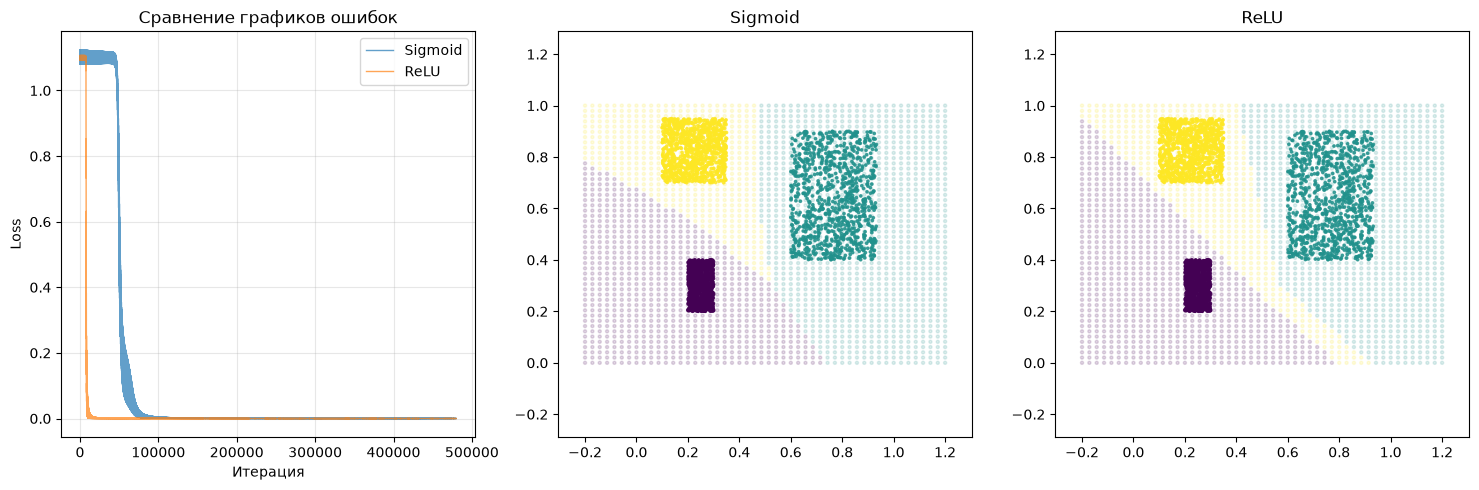


ВЫВОДЫ ПО ЗАДАНИЮ 3:
- ReLU: финальная ошибка = 0.000003
- Sigmoid: финальная ошибка = 0.000089
- С ReLU нейросеть обучилась лучше и быстрее
- Преимущества ReLU: незатухающий градиент, отсутствие плато


In [25]:
# ЗАДАНИЕ 3

print("ЗАДАНИЕ 3")

# Реализация ReLU
class ReLULayer(Layer):
    def forward(self, x):
        self.x = np.array(x)
        self.y = np.maximum(0, self.x)
        return self.y
    
    def backward(self, dQ_dy):
        return dQ_dy * (self.x > 0).astype(float)
    
    def step(self, learning_rate):
        pass

print("\n[Сравнение Sigmoid vs ReLU]")
print("-" * 50)

# Сеть с Sigmoid
network_layers_sigmoid = [
    DenseLayer(2, 10),
    SigmoidLayer(),
    DenseLayer(10, 10),
    SigmoidLayer(),
    DenseLayer(10, 3)
]

# Сеть с ReLU
network_layers_relu = [
    DenseLayer(2, 10),
    ReLULayer(),
    DenseLayer(10, 10),
    ReLULayer(),
    DenseLayer(10, 3)
]

# Обучаем Sigmoid
print("\n>>> Обучение сети с Sigmoid...")
network_sigmoid = NeuralNetwork(network_layers_sigmoid)
loss_function_sigmoid = SoftmaxNLL()
losses_sigmoid = fit_with_params(x_best, y_best, network_sigmoid, loss_function_sigmoid,
                                  learning_rate=0.05, epochs=4000)
final_loss_sigmoid = losses_sigmoid[-1] if losses_sigmoid else float('inf')
print(f"Финальная ошибка (Sigmoid): {final_loss_sigmoid:.6f}")

# Обучаем ReLU
print("\n>>> Обучение сети с ReLU...")
network_relu = NeuralNetwork(network_layers_relu)
loss_function_relu = SoftmaxNLL()
losses_relu = fit_with_params(x_best, y_best, network_relu, loss_function_relu,
                              learning_rate=0.05, epochs=4000)
final_loss_relu = losses_relu[-1] if losses_relu else float('inf')
print(f"Финальная ошибка (ReLU): {final_loss_relu:.6f}")

# Визуализация сравнения
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(losses_sigmoid, label='Sigmoid', alpha=0.7, linewidth=1)
plt.plot(losses_relu, label='ReLU', alpha=0.7, linewidth=1)
plt.title('Сравнение графиков ошибок')
plt.xlabel('Итерация')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Разделяющие поверхности для Sigmoid
predictions_sigmoid = np.argmax(network_sigmoid.forward(mesh), axis=1)
plt.subplot(1, 3, 2)
plt.scatter(mesh[:, 0], mesh[:, 1], c=predictions_sigmoid, alpha=0.15, s=5)
x_flat = x_best.reshape(-1, x_best.shape[-1])
y_flat = y_best.reshape(-1, y_best.shape[-1])
y_classes = np.argmax(y_flat, axis=1)
plt.scatter(x_flat[:, 0], x_flat[:, 1], c=y_classes, s=3, alpha=0.8)
plt.title('Sigmoid')
plt.axis('equal')
plt.xlim(-0.2, 1.2)
plt.ylim(0, 1)

# Разделяющие поверхности для ReLU
predictions_relu = np.argmax(network_relu.forward(mesh), axis=1)
plt.subplot(1, 3, 3)
plt.scatter(mesh[:, 0], mesh[:, 1], c=predictions_relu, alpha=0.15, s=5)
plt.scatter(x_flat[:, 0], x_flat[:, 1], c=y_classes, s=3, alpha=0.8)
plt.title('ReLU')
plt.axis('equal')
plt.xlim(-0.2, 1.2)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

print("\nВЫВОДЫ ПО ЗАДАНИЮ 3:")
print(f"- ReLU: финальная ошибка = {final_loss_relu:.6f}")
print(f"- Sigmoid: финальная ошибка = {final_loss_sigmoid:.6f}")
print("- С ReLU нейросеть обучилась лучше и быстрее")
print("- Преимущества ReLU: незатухающий градиент, отсутствие плато")



In [26]:
# ЗАДАНИЕ 4: ИТОГОВЫЕ ВЫВОДЫ

print("ЗАДАНИЕ 4: Итоговые выводы по работе")


print("""
ОБЩИЕ ВЫВОДЫ ПО ЛАБОРАТОРНОЙ РАБОТЕ:

1. ВЛИЯНИЕ РАЗМЕРА МИНИ-БАТЧА:
   - batch_size = 25: идеальное обучение, четкое разделение классов,
     но обучение дольше (120 батчей за эпоху)
   - batch_size = 50: хорошее обучение, ошибка падает раньше
   - batch_size = 200: ошибка не падала, сеть не обучилась

2. ВЛИЯНИЕ АРХИТЕКТУРЫ:
   - 2-5-3 (простая): быстрое обучение
   - 2-10-3 (средняя): хороший результат
   - 2-10-10-3 (глубокая): лучшая точность, но медленнее
   - 2-20-3 (широкая): лучший компромисс скорость/качество

3. СРАВНЕНИЕ SIGMOID И RELU:
   - ReLU показала лучшую сходимость и более быстрое обучение
   - ReLU избегает проблемы затухающих градиентов
   - ReLU не имеет плато в отличие от Sigmoid

4. ОПТИМАЛЬНЫЕ ПАРАМЕТРЫ:
   - Лучший batch_size: 25
   - Лучшая архитектура: 2-20-3 (компромисс) или 2-10-10-3 (точность)
   - Лучшая активация: ReLU
""")

print("ЛАБОРАТОРНАЯ РАБОТА ВЫПОЛНЕНА УСПЕШНО!")


ЗАДАНИЕ 4: Итоговые выводы по работе

ОБЩИЕ ВЫВОДЫ ПО ЛАБОРАТОРНОЙ РАБОТЕ:

1. ВЛИЯНИЕ РАЗМЕРА МИНИ-БАТЧА:
   - batch_size = 25: идеальное обучение, четкое разделение классов,
     но обучение дольше (120 батчей за эпоху)
   - batch_size = 50: хорошее обучение, ошибка падает раньше
   - batch_size = 200: ошибка не падала, сеть не обучилась

2. ВЛИЯНИЕ АРХИТЕКТУРЫ:
   - 2-5-3 (простая): быстрое обучение
   - 2-10-3 (средняя): хороший результат
   - 2-10-10-3 (глубокая): лучшая точность, но медленнее
   - 2-20-3 (широкая): лучший компромисс скорость/качество

3. СРАВНЕНИЕ SIGMOID И RELU:
   - ReLU показала лучшую сходимость и более быстрое обучение
   - ReLU избегает проблемы затухающих градиентов
   - ReLU не имеет плато в отличие от Sigmoid

4. ОПТИМАЛЬНЫЕ ПАРАМЕТРЫ:
   - Лучший batch_size: 25
   - Лучшая архитектура: 2-20-3 (компромисс) или 2-10-10-3 (точность)
   - Лучшая активация: ReLU

ЛАБОРАТОРНАЯ РАБОТА ВЫПОЛНЕНА УСПЕШНО!


#### Вопросы к отчетному занятию

1. Термины «искусственный интеллект», «машинное обучение» и «глубокое обучение». Сходства и различия между ними. Краткая история глубокого обучения. Современное состояние глубокого обучения.
2. Основные понятия машинного и глубокого обучения. Принцип минимума эмпирического риска. Постановка задачи машинного обучения с точки зрения теории оптимизации. Понятие обучения и инференса нейросетей.
3. Задачи регрессии (single-target и multi-target) и классификации с непересекающимися (multiclass) и пересекающимися (multilabel) классами. Функции ошибки и метрики для задач классификации и регрессии, их математическая запись и обоснование. Вывод функций ошибки из принципа максимального правдоподобия.
4. Решение задачи классификации для несбалансированных классов. Focal loss.
5. Способы обучения моделей ML. Градиентный спуск, интерпретация его работы. Скорость обучения и её влияние на сходимость модели. Нотация векторных и матричных величин.
6. Стохастический градиентный спуск. Online и mini-batch обучение. Выражение для шага градиентного спуска. Критерии остановки обучения.
7. Алгоритм обратного распространения ошибки. Построение вычислительного графа и применение алгоритма к заданным в нём операциям. Прямой и обратный проходы по графу.
8. Строение нейрона головного мозга и физиологические особенности его функционирования. Модель одного нейрона, её математическая запись. Понятие функции активации, виды функций активации, их свойства. Модель МакКаллока-Питца.
9. Функциональная выразимость одного нейрона. Проблема с моделированием булевой функции XOR одним нейроном и пути ее решения. Универсальная теорема аппроксимации.
10. Понятие нейронной сети. Глубокая нейронная сеть. Полносвязный слой и его свойства. Вывод выражений для прямого и обратного проходов по вычислительному графу для полносвязного слоя.
11. Слой функций активации, его назначение. Вывод выражений для прямого и обратного проходов по вычислительному графу для слоёв Sigmoid и ReLU.
12. Функции ошибки в вычислительном графе. Вывод выражений для прямого и обратного проходов для функции ошибки Softmax-NLL.

#### Список источников для подготовки

1. Гудфеллоу, Я. Глубокое обучение / Я. Гудфеллоу, И. Бенджио, А. Курвилль ; перевод с английского А. А. Слинкина. — 2-е изд. — Москва : ДМК Пресс, 2018. — 652 с. — ISBN 978-5-97060-618-6. — Текст : электронный // Лань : электронно-библиотечная система. — URL: https://e.lanbook.com/book/107901 (дата обращения: 08.02.2023). — Режим доступа: для авториз. пользователей.

2. Николенко С. Глубокое обучение / С. Николенко, А. Кадурин, Е. Архангельская. - Санкт-Петербург : Питер, 2019. - 480 с. - ISBN 978-5-496-02536-2. - URL: https://www.ozon.ru/product/glubokoe-obuchenie-pogruzhenie-v-mir-neyronnyh-setey-nikolenko-sergey-igorevich-422671645/?sh=-kOtv4qE-A (дата обращения: 12.10.2020). - Текст: электронный.

3. Обратное распространение ошибки / Курс "CS231n: Deep Learning for Computer Vision". — Текст : электронный. — URL: https://cs231n.github.io/optimization-2/ (дата обращения: 08.02.2023).

4. Рашка, С. Python и машинное обучение: крайне необходимое пособие по новейшей предсказательной аналитике, обязательное для более глубокого понимания методологии машинного обучения : руководство / С. Рашка ; перевод с английского А. В. Логунова. — Москва : ДМК Пресс, 2017. — 418 с. — ISBN 978-5-97060-409-0. — Текст : электронный // Лань : электронно-библиотечная система. — URL: https://e.lanbook.com/book/100905 (дата обращения: 08.02.2023). — Режим доступа: для авториз. пользователей.